# Final Project: Hotel Booking Data Analysis

**Course:** Data Processing with Python (CA25 Customer Projects, HAMK)
**Group members:**
1. Anup Kandel
2. Sandesh Bishokarma
3. Sushant Koirala
4. Tanka Raj Aryal

> **Starter template.** Every block marked `TODO` is work your group must finish.
> The ready-made code covers setup, checks and the required derived variables so you can
> spend your time on the analysis, the decisions and the interpretation, which is where the marks are.
> Before you submit, delete this note and every `TODO` line.

> **Sandesh's working copy** (`notebooks/work/Sandesh.ipynb`). Only my tasks are filled in:
> - **#1** proposed research questions (section 1), to confirm with the group at kickoff
> - **#8** RQ1: hotel × cancellation crosstab (+ deposit type), Figure 1 and its interpretation
> - **#9** RQ2: lead time grouped by cancellation status, Figure 3 and its interpretation
>
> Everything else is still the team's TODO. Cleaning (section 4) is not applied yet, so my numbers use all 1,000 rows;
> the integrator re-runs them after Tanka's cleaning is merged, and the small differences will update automatically.

## 1. Context and research questions

**What one row represents:** TODO: one hotel booking (completed or cancelled) for ...

**Population and time period:** TODO: bookings at a city hotel (Lisbon) and a resort hotel (Algarve), Portugal,
with arrival dates from July 2015 to August 2017. This is a 1,000-record sample of the Hotel Booking Demand dataset
(António, de Almeida & Nunes, 2019).

**Purpose of the analysis:** TODO: 2–3 sentences. Who is the audience (hotel management)? What do you want to help them understand?

**Research questions** (together they must include a categorical comparison, a numerical variable,
and a relationship, grouped comparison or time pattern):

1. *(categorical comparison, proposed by Sandesh, #1)* Do cancellation rates differ between the City Hotel and the Resort Hotel?
2. *(numerical variable, proposed by Sandesh, #1)* Is lead time (days between booking and arrival) associated with cancellation?
3. *(time pattern, proposed by Sandesh, #1)* How does booking volume vary by arrival month for each hotel?

## 2. Imports and display settings

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.2f}".format)

DATA_FILE = "../../data/hotel_bookings_final_project.csv"   # the instructor's file: never overwrite it
# (paths start with ../../ because this copy is in notebooks/work/)
CLEAN_FILE = "../../outputs/hotel_bookings_cleaned.csv"
SUMMARY_FILE = "../../outputs/hotel_booking_summary.csv"

## 3. Load and inspect the data

In [2]:
raw = pd.read_csv(DATA_FILE)   # 'raw' stays unchanged for the whole notebook
print(f"Rows: {raw.shape[0]}, columns: {raw.shape[1]}")
raw.sample(5, random_state=42)

Rows: 1000, columns: 20


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,country,market_segment,deposit_type,customer_type,average_daily_rate,is_repeated_guest,booking_changes,required_car_parking_spaces,total_of_special_requests
521,City Hotel,0,190,2016,December,28,0,4,2,0,0,DEU,Direct,No Deposit,Transient,167.80,0,0,0,1
737,Resort Hotel,0,225,2016,May,26,0,3,1,0,0,GBR,Groups,No Deposit,Transient-Party,66.00,0,2,1,0
740,City Hotel,1,105,2017,June,26,1,3,2,0,0,CHE,Online TA,No Deposit,Transient,126.00,0,0,0,0
660,City Hotel,0,198,2017,March,17,1,2,2,0,1,NLD,Online TA,No Deposit,Transient,93.60,0,2,0,3
411,Resort Hotel,0,54,2016,January,9,2,2,2,0,0,GBR,Offline TA/TO,No Deposit,Transient,49.40,0,3,0,0


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   hotel                        1000 non-null   str    
 1   is_canceled                  1000 non-null   int64  
 2   lead_time                    1000 non-null   int64  
 3   arrival_date_year            1000 non-null   int64  
 4   arrival_date_month           1000 non-null   str    
 5   arrival_date_day_of_month    1000 non-null   int64  
 6   stays_in_weekend_nights      1000 non-null   int64  
 7   stays_in_week_nights         1000 non-null   int64  
 8   adults                       1000 non-null   int64  
 9   children                     1000 non-null   int64  
 10  babies                       1000 non-null   int64  
 11  country                      998 non-null    str    
 12  market_segment               1000 non-null   str    
 13  deposit_type                 1

In [4]:
# Missing values and exact duplicates
missing = raw.isna().sum()
print("Missing values per column (only columns with any):")
print(missing[missing > 0])
print("\nExact duplicate rows:", raw.duplicated().sum())

Missing values per column (only columns with any):
country    2
dtype: int64

Exact duplicate rows: 26


In [5]:
# Useful category counts
for col in ["hotel", "is_canceled", "market_segment", "deposit_type", "customer_type"]:
    print(f"--- {col} ---")
    print(raw[col].value_counts(dropna=False), "\n")

--- hotel ---
hotel
City Hotel      642
Resort Hotel    358
Name: count, dtype: int64 

--- is_canceled ---
is_canceled
0    634
1    366
Name: count, dtype: int64 

--- market_segment ---
market_segment
Online TA        481
Offline TA/TO    209
Groups           163
Direct           100
Corporate         41
Complementary      6
Name: count, dtype: int64 

--- deposit_type ---
deposit_type
No Deposit    881
Non Refund    116
Refundable      3
Name: count, dtype: int64 

--- customer_type ---
customer_type
Transient          742
Transient-Party    226
Contract            28
Group                4
Name: count, dtype: int64 


In [6]:
# Numerical summary statistics
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,1000.00,0.37,0.48,0.00,0.00,0.00,1.00,1.00
lead_time,1000.00,105.06,106.45,0.00,19.00,69.50,157.00,542.00
arrival_date_year,1000.00,2016.13,0.70,2015.00,2016.00,2016.00,2017.00,2017.00
arrival_date_day_of_month,1000.00,16.13,8.96,1.00,8.00,16.00,24.00,31.00
stays_in_weekend_nights,1000.00,0.92,0.95,0.00,0.00,1.00,2.00,8.00
stays_in_week_nights,1000.00,2.52,1.80,0.00,1.00,2.00,3.00,20.00
adults,1000.00,1.86,0.53,0.00,2.00,2.00,2.00,6.00
children,1000.00,0.11,0.40,0.00,0.00,0.00,0.00,3.00
babies,1000.00,0.01,0.09,0.00,0.00,0.00,0.00,1.00
average_daily_rate,1000.00,101.21,45.72,0.00,68.57,94.50,125.00,304.00


## 4. Data-quality assessment and cleaning log

Run the checks below first, then fill in the cleaning log with **your group's decisions**.
There is often no single right answer. You get marks for showing the evidence and justifying the decision.

In [7]:
# Helper columns used only for the checks
check = raw.copy()
check["nights_tmp"] = check["stays_in_weekend_nights"] + check["stays_in_week_nights"]
check["guests_tmp"] = check["adults"] + check["children"] + check["babies"]
check["date_tmp"] = pd.to_datetime(
    check["arrival_date_year"].astype(str) + "-" + check["arrival_date_month"] + "-"
    + check["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d", errors="coerce")

def iqr_upper_fence(series):
    """Return the 1.5*IQR upper fence used to flag unusually large values."""
    q1, q3 = series.quantile([0.25, 0.75])
    return q3 + 1.5 * (q3 - q1)

numeric_cols = raw.select_dtypes("number").columns
checks = {
    "missing values (any column)": raw.isna().any(axis=1).sum(),
    "exact duplicate rows": raw.duplicated().sum(),
    "invalid date combinations": check["date_tmp"].isna().sum(),
    "rows with a negative numeric value": (raw[numeric_cols] < 0).any(axis=1).sum(),
    "zero total guests": (check["guests_tmp"] == 0).sum(),
    "zero total nights": (check["nights_tmp"] == 0).sum(),
    "lead_time above IQR fence": (raw["lead_time"] > iqr_upper_fence(raw["lead_time"])).sum(),
    "average_daily_rate above IQR fence": (raw["average_daily_rate"] > iqr_upper_fence(raw["average_daily_rate"])).sum(),
    "average_daily_rate == 0": (raw["average_daily_rate"] == 0).sum(),
}
pd.Series(checks, name="affected rows").to_frame()

,affected rows
missing values (any column),2
exact duplicate rows,26
invalid date combinations,0
rows with a negative numeric value,0
zero total guests,3
zero total nights,5
lead_time above IQR fence,28
average_daily_rate above IQR fence,25
average_daily_rate == 0,15


In [8]:
# Look at the affected rows before deciding. Example: zero-night and zero-guest bookings
check.loc[(check["nights_tmp"] == 0) | (check["guests_tmp"] == 0),
          ["hotel", "is_canceled", "adults", "children", "babies", "nights_tmp", "average_daily_rate", "market_segment"]]

,hotel,is_canceled,adults,children,babies,nights_tmp,average_daily_rate,market_segment
201,City Hotel,0,0,0,0,0,0.00,Online TA
455,Resort Hotel,0,1,0,0,0,0.00,Groups
461,City Hotel,0,1,0,0,0,0.00,Offline TA/TO
774,City Hotel,0,0,0,0,0,0.00,Offline TA/TO
993,City Hotel,0,0,0,0,0,0.00,Online TA


In [9]:
# TODO: inspect the other issues the same way, e.g.
# raw[raw.duplicated(keep=False)].sort_values(list(raw.columns)).head(10)
# raw.loc[raw["average_daily_rate"] == 0, "market_segment"].value_counts()
# raw.nlargest(5, "lead_time")

### Cleaning log

| Issue checked | Evidence | Decision | Reason |
|---|---|---|---|
| Missing `country` | TODO: n rows | TODO: keep / fill "Unknown" / remove | TODO |
| Exact duplicates | TODO: n rows | TODO | TODO: the dataset has no booking ID, so are these really repeated records, or separate identical bookings (e.g. a group)? |
| Invalid date combinations | TODO | TODO | TODO |
| Negative values | TODO | TODO | TODO |
| Zero total guests | TODO | TODO | TODO |
| Zero total nights | TODO | TODO | TODO |
| Unusual `lead_time` | TODO | TODO | TODO: are long lead times impossible, or just rare? |
| Unusual `average_daily_rate` (incl. 0) | TODO | TODO | TODO: look at `market_segment` (e.g. Complementary) |

In [10]:
clean = raw.copy()   # cleaned copy, 'raw' stays untouched
rows_before = len(clean)

# TODO: apply YOUR decisions from the cleaning log, for example:
# clean = clean.drop_duplicates()
# clean["country"] = clean["country"].fillna("Unknown")
# clean = clean[(clean["adults"] + clean["children"] + clean["babies"]) > 0]

print(f"Rows before cleaning: {rows_before}, after cleaning: {len(clean)}")

Rows before cleaning: 1000, after cleaning: 1000


## 5. Transformations and derived variables

In [11]:
clean["arrival_date"] = pd.to_datetime(
    clean["arrival_date_year"].astype(str) + "-" + clean["arrival_date_month"] + "-"
    + clean["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d", errors="coerce")
clean["total_nights"] = clean["stays_in_weekend_nights"] + clean["stays_in_week_nights"]
clean["total_guests"] = clean["adults"] + clean["children"] + clean["babies"]
clean["estimated_booking_value"] = clean["average_daily_rate"] * clean["total_nights"]

# Optional extra variables that may help your questions
clean["cancel_status"] = clean["is_canceled"].map({0: "Not cancelled", 1: "Cancelled"})
clean["arrival_month_num"] = clean["arrival_date"].dt.month

clean[["arrival_date", "total_nights", "total_guests", "average_daily_rate", "estimated_booking_value"]].head()

,arrival_date,total_nights,total_guests,average_daily_rate,estimated_booking_value
0,2015-09-30,2,1,98.10,196.20
1,2016-03-19,6,2,70.17,421.02
2,2017-08-01,4,2,193.40,773.60
3,2016-11-11,1,2,36.24,36.24
4,2017-07-27,2,2,89.10,178.20


## 6. Individual-variable analysis

At least **two categorical** variables (counts, %, n, bar chart) and **two numerical** variables
(n, mean, median, std, min, max, histogram or box plot).

In [12]:
def categorical_summary(df, column):
    """Counts and percentages for one categorical column, with the valid n."""
    counts = df[column].value_counts()
    table = pd.DataFrame({"count": counts, "percent": (counts / counts.sum() * 100).round(1)})
    print(f"{column}: valid n = {counts.sum()}")
    return table

def numerical_summary(df, columns):
    """Valid n, mean, median, std, min and max for numeric columns."""
    return df[columns].agg(["count", "mean", "median", "std", "min", "max"]).T.rename(columns={"count": "valid_n"})

categorical_summary(clean, "hotel")

hotel: valid n = 1000


,count,percent
hotel,,
City Hotel,642,64.20
Resort Hotel,358,35.80


In [13]:
# TODO: second categorical variable, e.g. deposit_type or market_segment, with a bar chart

In [14]:
numerical_summary(clean, ["lead_time", "average_daily_rate"])

,valid_n,mean,median,std,min,max
lead_time,1000.00,105.06,69.50,106.45,0.00,542.00
average_daily_rate,1000.00,101.21,94.50,45.72,0.00,304.00


In [15]:
# TODO: histogram or box plot for each numerical variable. Template:
# fig, ax = plt.subplots(figsize=(8, 4))
# ax.hist(clean["lead_time"], bins=30, edgecolor="white")
# ax.set_title(f"Distribution of lead time (n = {clean['lead_time'].notna().sum()})")
# ax.set_xlabel("Lead time (days)"); ax.set_ylabel("Number of bookings")
# plt.show()

## 7. Relationships and grouped analysis

Required: **categorical × categorical** (crosstab, counts + labelled %), **categorical × numerical** (`groupby` + aggregation),
and **numerical × numerical or time-based**.

### 7.1 RQ1: hotel × cancellation status (Sandesh, #8)

In [16]:
# Categorical x categorical: hotel x cancellation
counts = pd.crosstab(clean["hotel"], clean["cancel_status"], margins=True, margins_name="Total")
row_pct = (pd.crosstab(clean["hotel"], clean["cancel_status"], normalize="index") * 100).round(1)
print("Counts:")
display(counts)
print("Row percentages (denominator = all bookings for that hotel):")
display(row_pct)

Counts:


cancel_status,Cancelled,Not cancelled,Total
hotel,,,
City Hotel,279,363,642
Resort Hotel,87,271,358
Total,366,634,1000


Row percentages (denominator = all bookings for that hotel):


cancel_status,Cancelled,Not cancelled
hotel,,
City Hotel,43.50,56.50
Resort Hotel,24.30,75.70


**Denominator:** each row percentage is out of **all bookings for that hotel**, so each row adds up to 100 %.
City Hotel bookings were cancelled in **43.5 %** of cases (279 of 642), compared with **24.3 %** (87 of 358) at the Resort Hotel,
a gap of about 19 percentage points.

In [17]:
# Optional (#8): deposit type x cancellation
deposit_counts = pd.crosstab(clean["deposit_type"], clean["cancel_status"], margins=True, margins_name="Total")
deposit_pct = (pd.crosstab(clean["deposit_type"], clean["cancel_status"], normalize="index") * 100).round(1)
print("Counts:")
display(deposit_counts)
print("Row percentages (denominator = all bookings with that deposit type):")
display(deposit_pct)

Counts:


cancel_status,Cancelled,Not cancelled,Total
deposit_type,,,
No Deposit,250,631,881
Non Refund,116,0,116
Refundable,0,3,3
Total,366,634,1000


Row percentages (denominator = all bookings with that deposit type):


cancel_status,Cancelled,Not cancelled
deposit_type,,
No Deposit,28.40,71.60
Non Refund,100.00,0.00
Refundable,0.00,100.00


**Denominator:** all bookings with that deposit type. All 116 *Non Refund* bookings were cancelled, against 28.4 % of
*No Deposit* bookings (n = 881). This is unusual, because guests rarely cancel bookings they cannot get refunded, so it may
reflect how the source data recorded these bookings. We report it with caution and make no causal claim.

### 7.2 RQ2: lead time by cancellation status (Sandesh, #9)

In [18]:
# Categorical x numerical: lead time grouped by cancellation status
lead_summary = (
    clean.groupby("cancel_status", observed=True)
    .agg(
        bookings=("lead_time", "count"),
        average_lead_time=("lead_time", "mean"),
        median_lead_time=("lead_time", "median"),
        std_lead_time=("lead_time", "std"),
    )
    .sort_values("median_lead_time")
    .round(2)
)
lead_summary

,bookings,average_lead_time,median_lead_time,std_lead_time
cancel_status,,,,
Not cancelled,634,83.46,48.00,93.90
Cancelled,366,142.49,117.00,116.21


In [19]:
# Cancellation rate by lead-time band (pd.cut, as in the 01_Pandas_Concepts lesson)
lead_band = pd.cut(
    clean["lead_time"],
    bins=[-1, 7, 30, 90, 180, 365, float("inf")],
    labels=["0-7", "8-30", "31-90", "91-180", "181-365", "366+"],
)
band_summary = (
    clean.groupby(lead_band, observed=True)
    .agg(
        bookings=("is_canceled", "count"),
        cancelled=("is_canceled", "sum"),
        cancel_rate_pct=("is_canceled", "mean"),
    )
)
band_summary["cancel_rate_pct"] = (band_summary["cancel_rate_pct"] * 100).round(1)
band_summary.index.name = "lead time (days)"
band_summary

,bookings,cancelled,cancel_rate_pct
lead time (days),,,
0-7,145,20,13.80
8-30,170,45,26.50
31-90,253,86,34.00
91-180,220,94,42.70
181-365,184,103,56.00
366+,28,18,64.30


In [20]:
# Optional (#9): median daily rate and lead time by hotel
hotel_medians = (
    clean.groupby("hotel", observed=True)
    .agg(
        bookings=("hotel", "count"),
        median_adr=("average_daily_rate", "median"),
        median_lead_time=("lead_time", "median"),
    )
    .round(2)
)
hotel_medians

,bookings,median_adr,median_lead_time
hotel,,,
City Hotel,642,100.00,74.00
Resort Hotel,358,77.00,60.50


Cancelled bookings were made much further ahead: median lead time **117 days**, compared with **48 days** for bookings
that were kept (mean 142 vs 83 days). The cancellation rate rises in every lead-time band, from **13.8 %** for bookings made
within a week of arrival to **64.3 %** for bookings made more than a year ahead (only 28 bookings, so this last band is small).
This is an **association**: booking early does not by itself cause a cancellation.

In [21]:
# TODO: time-based or numerical x numerical, e.g. monthly booking counts by hotel:
# monthly = clean.groupby([clean["arrival_date"].dt.to_period("M"), "hotel"]).size().unstack()

## 8. Final visualizations

At least **four** finished charts: a categorical comparison, a numerical distribution,
a relationship / grouped comparison, and a time-based or multi-group figure.
Each one needs a title, axis labels, a legend if needed, n, and a **What can we observe?** paragraph.

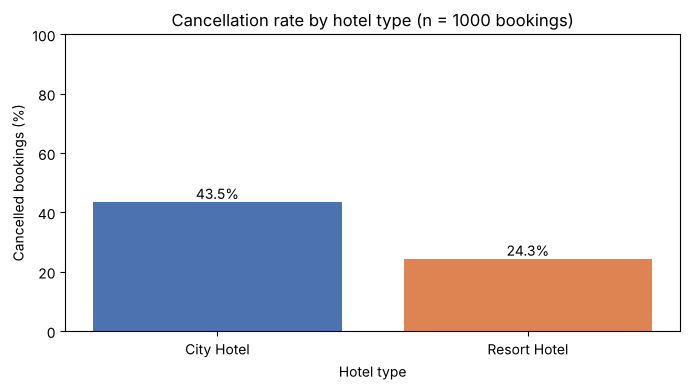

In [22]:
# Figure 1 (example): cancellation rate by hotel
rate = clean.groupby("hotel")["is_canceled"].agg(["mean", "count"])
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(rate.index, rate["mean"] * 100, color=["#4C72B0", "#DD8452"])
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in rate["mean"] * 100])
ax.set_title(f"Cancellation rate by hotel type (n = {rate['count'].sum()} bookings)")
ax.set_xlabel("Hotel type")
ax.set_ylabel("Cancelled bookings (%)")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

**What can we observe?** *(Sandesh, #8)* City Hotel bookings were cancelled more often: 43.5 % of its 642 bookings,
compared with 24.3 % of the Resort Hotel's 358. The chart shows a clear difference between the hotels, but not *why*;
the two hotels also differ in customers, booking channels and lead times.

In [23]:
# TODO: Figure 2 – numerical distribution

**What can we observe?** TODO

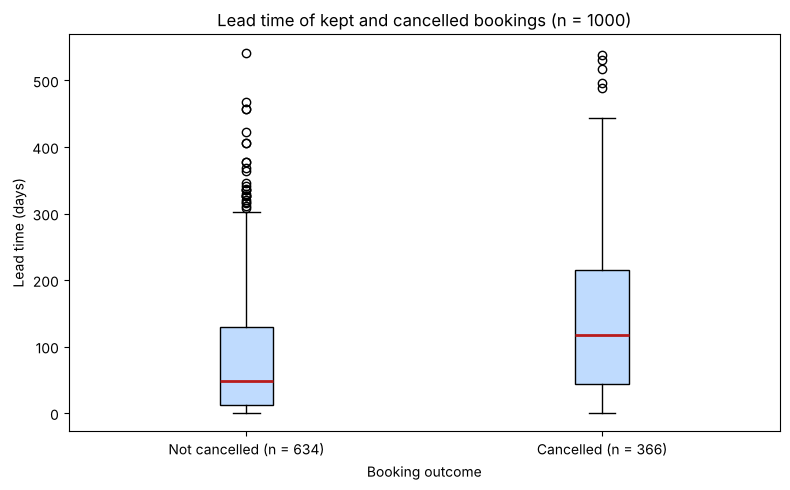

In [24]:
# Figure 3 (Sandesh, #9): lead time of kept vs cancelled bookings
groups = ["Not cancelled", "Cancelled"]
lead_by_group = [clean.loc[clean["cancel_status"] == g, "lead_time"] for g in groups]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(
    lead_by_group,
    tick_labels=[f"{g} (n = {len(d)})" for g, d in zip(groups, lead_by_group)],
    patch_artist=True,
    boxprops={"facecolor": "#bfdbfe"},
    medianprops={"color": "#b91c1c", "linewidth": 2},
)
ax.set_title(f"Lead time of kept and cancelled bookings (n = {len(clean)})")
ax.set_xlabel("Booking outcome")
ax.set_ylabel("Lead time (days)")
fig.tight_layout()
plt.show()

**What can we observe?** *(Sandesh, #9)* The whole box for cancelled bookings sits higher: their median lead time is
117 days, compared with 48 days for kept bookings, and 13 of the 20 bookings made more than 400 days ahead were cancelled.
Lead time is **associated** with cancellation in this sample; we cannot say that booking early *causes* a cancellation.

In [25]:
# TODO: Figure 4 – time-based or multi-group figure (e.g. monthly bookings, one line per hotel)

**What can we observe?** TODO

## 9. Exports and verification

In [26]:
# Section 9 (exports) is done by the integrator in the master notebook (#12),
# so this personal copy does not write files to outputs/.
# # TODO: replace this example with the summary table your group finds most useful
# summary = (clean.groupby("hotel")
#            .agg(bookings=("is_canceled", "size"),
#                 cancellation_rate_pct=("is_canceled", lambda s: round(s.mean() * 100, 1)),
#                 mean_lead_time=("lead_time", "mean"),
#                 mean_adr=("average_daily_rate", "mean"),
#                 mean_total_nights=("total_nights", "mean"))
#            .round(2)
#            .reset_index())
#
# clean.to_csv(CLEAN_FILE, index=False)
# summary.to_csv(SUMMARY_FILE, index=False)
#
# # Read both files back and verify them
# check_clean = pd.read_csv(CLEAN_FILE, parse_dates=["arrival_date"])
# check_summary = pd.read_csv(SUMMARY_FILE)
# print("Cleaned file shape:", check_clean.shape, "| matches:", check_clean.shape == clean.shape)
# print("Derived columns present:",
#       all(c in check_clean.columns for c in ["arrival_date", "total_nights", "total_guests", "estimated_booking_value"]))
# print("Summary file shape:", check_summary.shape)
# check_summary

## 10. Conclusions, limitations and recommendation

**Answers to the research questions**
1. TODO
2. TODO
3. TODO

**Key findings (3–5, each backed by a number from the analysis)**
- TODO

**Limitations / cautions (at least 2)**
- TODO, e.g. a 1,000-booking sample from two hotels only, 2015–2017; associations are not causes.
- TODO

**Recommendation for hotel management:** TODO

**A next question these variables can't answer:** TODO, e.g. *why* guests cancel (there is no cancellation-reason variable).